In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [23]:
delay_report = pd.read_excel('D:/(JSN)DataScience/Lectures/TransitDelayProj/filtered_files/delay_final.xlsx')
weather_report = pd.read_excel('D:/(JSN)DataScience/Lectures/TransitDelayProj/filtered_files/weather_final.xlsx')

In [24]:
# Basis statistical analysis of weather
def weather_stats(df):
    """
    Analyze weather patterns for the given dataframe containing temperature, precipitation, and humidity data.

    Parameters:
    df (pandas.DataFrame): DataFrame with columns 'datetime', 'temp', 'precipitation', 'humidity'

    Returns:
    dict: Dictionary containing all weather statistics and analysis
    """
    # Input validation
    required_columns = ['datetime', 'temp', 'precipitation', 'humidity']
    if not all(col in df.columns for col in required_columns):
        raise ValueError("DataFrame missing required columns")

    def calculate_temperature_stats(data):
        """Calculate basic statistics for temperature"""
        return {
            'min': data['temp'].min(),
            'max': data['temp'].max(),
            'mean': data['temp'].mean(),
            'std': data['temp'].std(),
            'median': data['temp'].median(),
            'q25': data['temp'].quantile(0.25),
            'q75': data['temp'].quantile(0.75),
            'iqr': (data['temp'].quantile(0.75) - data['temp'].quantile(0.25))
        }

    def calculate_precipitation_stats(data):
        """Calculate basic statistics for precipitation"""
        return {
            'min': data['precipitation'].min(),
            'max': data['precipitation'].max(),
            'mean': data['precipitation'].mean(),
            'std': data['precipitation'].std(),
            'median': data['precipitation'].median(),
            'q25': data['precipitation'].quantile(0.25),
            'q75': data['precipitation'].quantile(0.75),
            'iqr': (data['precipitation'].quantile(0.75) - data['precipitation'].quantile(0.25))
        }

    def calculate_humidity_stats(data):
        """Calculate basic statistics for humidity"""
        return {
            'min': data['humidity'].min(),
            'max': data['humidity'].max(),
            'mean': data['humidity'].mean(),
            'std': data['humidity'].std(),
            'median': data['humidity'].median(),
            'q25': data['humidity'].quantile(0.25),
            'q75': data['humidity'].quantile(0.75),
            'iqr': (data['humidity'].quantile(0.75) - data['humidity'].quantile(0.25))
        }

    # Create copy and extract date
    df_copy = df.copy()
    df_copy['date'] = df_copy['datetime'].dt.date

    # Daily aggregations
    daily_stats = df_copy.groupby('date').agg(
        total_precipitation=('precipitation', 'sum'),
        avg_temperature=('temp', 'mean'),
        min_temperature=('temp', 'min'),
        max_temperature=('temp', 'max'),
        temp_std=('temp', 'std'),
        avg_humidity=('humidity', 'mean')
    )

    # Identify extreme weather days
    temp_threshold = df_copy['temp'].quantile(0.25)  # cold threshold
    precip_threshold = daily_stats['total_precipitation'].quantile(0.75)  # heavy precipitation threshold

    # Find days with both cold and heavy precipitation
    extreme_days = daily_stats[
        (daily_stats['avg_temperature'] <= temp_threshold) &
        (daily_stats['total_precipitation'] >= precip_threshold)
    ]

    # Find days with high temperature volatility
    volatile_days = daily_stats[
        daily_stats['temp_std'] > daily_stats['temp_std'].mean() + daily_stats['temp_std'].std()
    ]

    # Hourly patterns
    hourly_patterns = df_copy.groupby(df_copy['datetime'].dt.hour).agg(
        avg_temp=('temp', 'mean'),
        avg_precip=('precipitation', 'mean'),
        avg_humidity=('humidity', 'mean')
    )

    # Compile results
    results = {
        'temperature_stats': calculate_temperature_stats(df_copy),
        'precipitation_stats': calculate_precipitation_stats(df_copy),
        'humidity_stats': calculate_humidity_stats(df_copy),
        'daily_stats': daily_stats,
        'extreme_weather_days': extreme_days,
        'volatile_temperature_days': volatile_days,
        'hourly_patterns': hourly_patterns
    }

    # Print formatted results
    print("\n=== Weather Analysis Report ===\n")

    print("Temperature Statistics:")
    print(f"- Range: {results['temperature_stats']['min']:.2f}°C to {results['temperature_stats']['max']:.2f}°C")
    print(f"- Average: {results['temperature_stats']['mean']:.2f}°C")
    print(f"- Most Common Range (IQR): {results['temperature_stats']['q25']:.2f}°C to {results['temperature_stats']['q75']:.2f}°C\n")

    print("Precipitation Statistics:")
    print(f"- Maximum: {results['precipitation_stats']['max']:.2f}mm")
    print(f"- Average: {results['precipitation_stats']['mean']:.2f}mm")
    print(f"- Days with Heavy Precipitation: {len(extreme_days)}\n")

    print("Extreme Weather Days:")
    for date in extreme_days.index:
        print(f"- {date}: Avg Temp: {extreme_days.loc[date, 'avg_temperature']:.2f}°C, "
              f"Precipitation: {extreme_days.loc[date, 'total_precipitation']:.2f}mm")

    print("\nDays with High Temperature Volatility:")
    for date in volatile_days.index:
        print(f"- {date}: Std Dev: {volatile_days.loc[date, 'temp_std']:.2f}°C")

    return results

In [25]:
results = weather_stats(weather_report)
# Access specific results if needed
temp_stats = results['temperature_stats']
extreme_days = results['extreme_weather_days']


=== Weather Analysis Report ===

Temperature Statistics:
- Range: -14.10°C to 6.90°C
- Average: -1.29°C
- Most Common Range (IQR): -4.20°C to 2.30°C

Precipitation Statistics:
- Maximum: 5.40mm
- Average: 0.12mm
- Days with Heavy Precipitation: 0

Extreme Weather Days:

Days with High Temperature Volatility:
- 2024-01-13: Std Dev: 3.04°C
- 2024-01-14: Std Dev: 2.42°C
- 2024-01-20: Std Dev: 2.60°C
- 2024-01-21: Std Dev: 3.29°C


In [26]:
def delay_stats(df):
    required_columns = [
        'route', 'day', 'location', 'incident',
        'delay_minutes', 'gap_minutes', 'direction',
        'vehicle', 'datetime'
    ]
    if not all(col in df.columns for col in required_columns):
        raise ValueError("DataFrame missing required columns")

    # Create a working copy and extract date from datetime
    df_copy = df.copy()
    df_copy['date'] = df_copy['datetime'].dt.date

    # --- Basic Delay Statistics ---
    def delay_stats_basic(data):
        return {
            'min': data[data['delay_minutes'] != 0]['delay_minutes'].min(),
            'max': data['delay_minutes'].max(),
            'mean': data['delay_minutes'].mean(),
            'std': data['delay_minutes'].std(),
            'q25': data['delay_minutes'].quantile(0.25),
            'q75': data['delay_minutes'].quantile(0.75),
            'iqr': data['delay_minutes'].quantile(0.75) - data['delay_minutes'].quantile(0.25)
        }

    def gap_stats(data):
        return {
            'min': data[data['gap_minutes'] != 0]['gap_minutes'].min(),
            'max': data['gap_minutes'].max(),
            'mean': data['gap_minutes'].mean(),
            'std': data['gap_minutes'].std(),
            'q25': data['gap_minutes'].quantile(0.25),
            'q75': data['gap_minutes'].quantile(0.75),
            'iqr': data['gap_minutes'].quantile(0.75) - data['gap_minutes'].quantile(0.25)
        }

    # --- Route Analysis ---
    def route_stats(data):
        route_agg = data.groupby('route').agg(
            count=('route', 'count'),
            avg_delay=('delay_minutes', 'mean')
        )
        most_frequent_route = route_agg['count'].idxmax()
        max_count = route_agg['count'].max()

        highest_avg_route = route_agg['avg_delay'].idxmax()
        highest_avg_value = route_agg['avg_delay'].max()

        print(f'Most frequently delayed route is {most_frequent_route} with {max_count} delays in January')
        print(f'Route with the highest average delay is {highest_avg_route} and the delay is of {highest_avg_value} minutes')
        return route_agg

    # --- Directional Analysis ---
    def direction_stats(data):
        direction_agg = data.groupby('direction').agg(
            delays=('direction', 'count'),
            avg_delay=('delay_minutes', 'mean'),
        )
        most_affected_direction = direction_agg['delays'].idxmax()
        max_delay = direction_agg['delays'].max()
        print(f'Most affected direction is {most_affected_direction} with {max_delay} delays')
        return direction_agg

    # --- Temporal Patterns ---
    def temporal_stats(data):
        # Delays by day of week (using the 'day' column)
        day_agg = data.groupby('day').agg(
            delays=('delay_minutes', 'count'),
            avg_delay=('delay_minutes', 'mean')
        ).reset_index()

        # Extract hour from datetime and analyze hourly patterns
        data['hour'] = data['datetime'].dt.hour
        hour_agg = data.groupby('hour').agg(
            delays=('delay_minutes', 'count'),
            avg_delay=('delay_minutes', 'mean')
        ).reset_index()

        # Identify peak delay hour (highest count)
        peak_hour = hour_agg.loc[hour_agg['delays'].idxmax(), 'hour']
        print(f'Peak delay hour is {peak_hour} with {hour_agg["delays"].max()} delays')

        return {'day_agg': day_agg, 'hour_agg': hour_agg, 'peak_hour': peak_hour}

    # --- Location and Incident Analysis ---
    def location_incident_stats(data):
        # Analyze delays by location
        location_agg = data.groupby('location').agg(
            count=('location', 'count'),
            avg_delay=('delay_minutes', 'mean')
        ).reset_index().sort_values(by='count', ascending=False)
        most_common_location = location_agg.iloc[0]['location']
        print(f'Most common delay location is {most_common_location}')

        # Frequency of different incident types
        incident_freq = data['incident'].value_counts().reset_index()
        incident_freq.columns = ['incident', 'count']

        # Average delay duration by incident type
        incident_delay = data.groupby('incident').agg(
            avg_delay=('delay_minutes', 'mean')
        ).reset_index().sort_values(by='avg_delay', ascending=False)

        return {
            'location_agg': location_agg,
            'incident_freq': incident_freq,
            'incident_delay': incident_delay
        }

    # --- Vehicle Analysis ---
    def vehicle_stats(data):
        # Analyze delays per vehicle
        vehicle_agg = data.groupby('vehicle').agg(
            count=('vehicle', 'count'),
            avg_delay=('delay_minutes', 'mean')
        ).reset_index().sort_values(by='count', ascending=False)
        most_frequent_vehicle = vehicle_agg.iloc[1]['vehicle']
        max_vehicle_delays = vehicle_agg.iloc[1]['count']
        print(f'Most frequently delayed vehicle is {most_frequent_vehicle} with {max_vehicle_delays} delays')
        return vehicle_agg

    # --- Compile All Results ---
    results = {
        'basic_delay_stats': delay_stats_basic(df_copy),
        'gap_stats': gap_stats(df_copy),
        'route_stats': route_stats(df_copy),
        'direction_stats': direction_stats(df_copy),
        'temporal_stats': temporal_stats(df_copy),
        'location_incident_stats': location_incident_stats(df_copy),
        'vehicle_stats': vehicle_stats(df_copy)
    }

    return results

In [27]:
# Example usage:
results = delay_stats(delay_report)
basic_stats = results['basic_delay_stats']
vehicle_analysis = results['vehicle_stats']

Most frequently delayed route is 32 with 149 delays in January
Route with the highest average delay is 28 and the delay is of 181.0 minutes
Most affected direction is N with 1045 delays
Peak delay hour is 17 with 332 delays
Most common delay location is kennedy station
Most frequently delayed vehicle is 1387.0 with 10.0 delays


Merged Data (first 5 rows):
         date  total_delay  avg_delay  delay_count  avg_temp  \
0  2024-01-01         3944  40.244898           98 -1.712500   
1  2024-01-02         3376  19.858824          170 -0.116667   
2  2024-01-03         3142  16.983784          185  1.775000   
3  2024-01-04         3565  19.805556          180 -2.733333   
4  2024-01-05         4111  22.102151          186 -1.125000   

   total_precipitation  avg_humidity  
0                 21.7     74.208333  
1                  0.0     70.833333  
2                  0.0     75.458333  
3                  0.0     62.750000  
4                  0.0     62.375000  


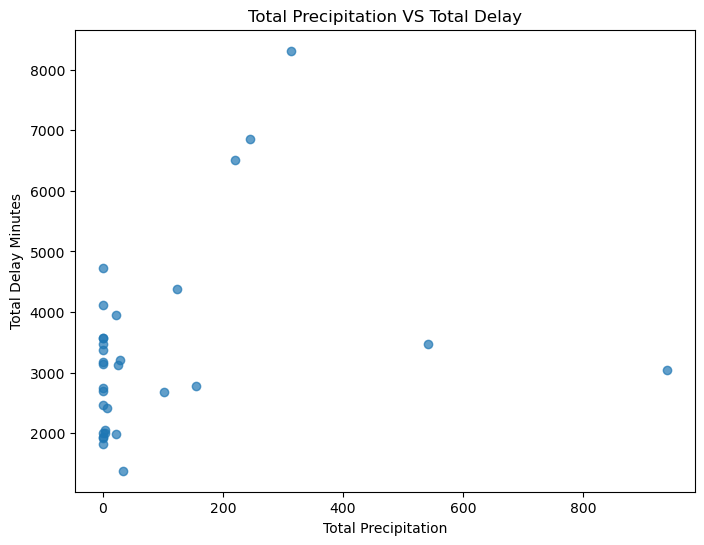

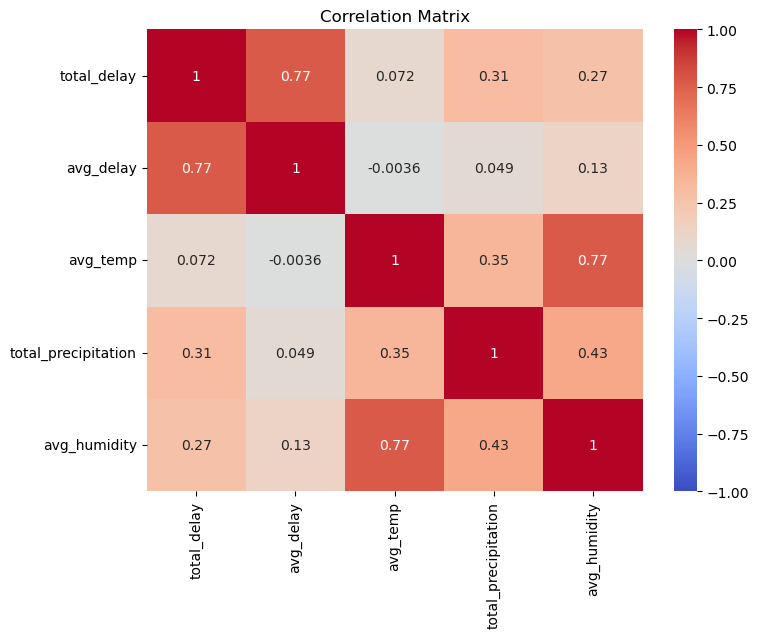

Correlation Matrix:
                     total_delay  avg_delay  avg_temp  total_precipitation  \
total_delay             1.000000   0.766770  0.072413             0.306968   
avg_delay               0.766770   1.000000 -0.003564             0.049265   
avg_temp                0.072413  -0.003564  1.000000             0.345537   
total_precipitation     0.306968   0.049265  0.345537             1.000000   
avg_humidity            0.270358   0.129135  0.767616             0.428762   

                     avg_humidity  
total_delay              0.270358  
avg_delay                0.129135  
avg_temp                 0.767616  
total_precipitation      0.428762  
avg_humidity             1.000000  

=== Observations ===

- Total Delay vs. Total Precipitation: r = 0.31
  -> There is a moderate positive correlation. This suggests that days with higher precipitation tend to have higher total delay minutes.

- Total Delay vs. Average Temperature: r = 0.07
  -> There is little or no correlatio

In [28]:
# Load your dataframes (assuming delay_report and weather_report are already loaded)
delay_df = delay_report.copy()
weather_df = weather_report.copy()

# Create a 'date' column in both datasets
delay_df['date'] = delay_df['datetime'].dt.date
weather_df['date'] = weather_df['datetime'].dt.date

# Aggregate delay data daily
daily_delay = delay_df.groupby('date').agg(
    total_delay=('delay_minutes', 'sum'),
    avg_delay=('delay_minutes', 'mean'),
    delay_count=('delay_minutes', 'count')
).reset_index()

# Aggregate weather data daily
daily_weather = weather_df.groupby('date').agg(
    avg_temp=('temp', 'mean'),
    total_precipitation=('precipitation', 'sum'),
    avg_humidity=('humidity', 'mean')
).reset_index()

# Merge both datasets on the date column
merged_df = pd.merge(daily_delay, daily_weather, on='date', how='inner')
print("Merged Data (first 5 rows):")
print(merged_df.head())

# Scatter plot: Total Precipitation vs. Total Delay Minutes
plt.figure(figsize=(8, 6))
plt.scatter(merged_df['total_precipitation'], merged_df['total_delay'], alpha=0.7)
plt.xlabel('Total Precipitation')
plt.ylabel('Total Delay Minutes')
plt.title('Total Precipitation VS Total Delay')
plt.show()

# Compute correlation matrix
correlation_matrix = merged_df[['total_delay', 'avg_delay', 'avg_temp', 'total_precipitation', 'avg_humidity']].corr()

# Heatmap of the correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

print("Correlation Matrix:")
print(correlation_matrix)

print("\n=== Observations ===")

# 1. Total Delay vs. Total Precipitation
corr_total_precip = correlation_matrix.loc['total_delay', 'total_precipitation']
print(f"\n- Total Delay vs. Total Precipitation: r = {corr_total_precip:.2f}")
if abs(corr_total_precip) >= 0.3:
    print(
        "  -> There is a moderate positive correlation. This suggests that days with higher precipitation tend to have higher total delay minutes.")
else:
    print("  -> The relationship is weak or negligible.")

# 2. Total Delay vs. Average Temperature
corr_total_temp = correlation_matrix.loc['total_delay', 'avg_temp']
print(f"\n- Total Delay vs. Average Temperature: r = {corr_total_temp:.2f}")
if abs(corr_total_temp) >= 0.3:
    print("  -> A moderate or strong correlation exists, indicating that temperature might influence delays.")
else:
    print("  -> There is little or no correlation between temperature and total delay minutes.")

# 3. Total Delay vs. Average Humidity
corr_total_humid = correlation_matrix.loc['total_delay', 'avg_humidity']
print(f"\n- Total Delay vs. Average Humidity: r = {corr_total_humid:.2f}")
if abs(corr_total_humid) >= 0.3:
    print(
        "  -> There is a moderate positive relationship, which may suggest higher humidity is associated with higher total delays.")
else:
    print("  -> The correlation is weak, so humidity may not be a major factor for total delay minutes.")

# 4. Average Delay vs. Weather Metrics
corr_avg_delay_precip = correlation_matrix.loc['avg_delay', 'total_precipitation']
print(f"\n- Average Delay vs. Total Precipitation: r = {corr_avg_delay_precip:.2f}")
print(
    "  -> The correlation is nearly zero, indicating that while more rain might lead to more delay events (affecting total delay), the average delay per event does not seem strongly affected by precipitation.")

corr_avg_delay_temp = correlation_matrix.loc['avg_delay', 'avg_temp']
print(f"\n- Average Delay vs. Average Temperature: r = {corr_avg_delay_temp:.2f}")
print(
    "  -> The negligible correlation suggests that temperature does not have a strong impact on the average delay per event.")

corr_avg_delay_humid = correlation_matrix.loc['avg_delay', 'avg_humidity']
print(f"\n- Average Delay vs. Average Humidity: r = {corr_avg_delay_humid:.2f}")
print(
    "  -> Again, a very weak correlation implies that humidity isn’t strongly linked to the severity (average) of delays.")

# 5. Other observations
print("\nAdditional Observations:")
print(
    "- The very high correlation between total_delay and avg_delay (r ≈ 0.77) is expected, as both metrics are derived from the same data.")
print(
    "- Weather variables (avg_temp, total_precipitation, avg_humidity) do not show a strong relationship with the average delay per event.")
print(
    "- The moderate positive correlation between total_delay and total_precipitation suggests that rain might increase the number of delay minutes in a day (perhaps by increasing the number of delay events), even if each individual delay is not necessarily longer.")
